--correlation=3

/usr/local/lib/python3.13/dist-packages/e3nn/o3/_wigner.py:10: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  _Jd, _W3j_flat, _W3j_indices = torch.load(os.path.join(os.path.dirname(__file__), 'constants.pt'))


cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.
Mounted at /content/drive
Loading MACE model and structure...


/usr/local/lib/python3.13/dist-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)



--- PHASE 1: Relaxing to 0K Equilibrium ---
       Step     Time          Energy          fmax
LBFGS:    0 09:25:04     -479.407990        0.968455
LBFGS:    1 09:25:04     -479.601501        0.913372
LBFGS:    2 09:25:05     -479.994019        1.044977
LBFGS:    3 09:25:06     -480.398987        1.497672
LBFGS:    4 09:25:07     -480.734558        0.921695
LBFGS:    5 09:25:07     -480.927948        0.480259
LBFGS:    6 09:25:08     -481.071686        0.479136
LBFGS:    7 09:25:08     -481.198181        0.667274
LBFGS:    8 09:25:08     -481.306671        0.559933
LBFGS:    9 09:25:08     -481.390411        0.544284
LBFGS:   10 09:25:08     -481.463196        0.401685
LBFGS:   11 09:25:08     -481.539856        0.475172
LBFGS:   12 09:25:08     -481.616272        0.416826
LBFGS:   13 09:25:08     -481.684540        0.425993
LBFGS:   14 09:25:09     -481.747711        0.412130
LBFGS:   15 09:25:09     -481.812561        0.387313
LBFGS:   16 09:25:09     -481.880219        0.374474
LBF

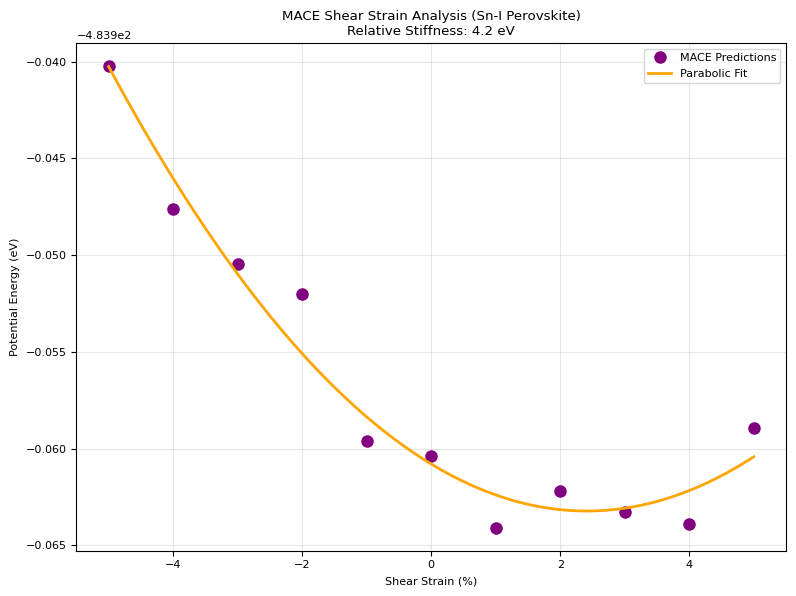

Analysis complete! Plot saved to /content/mace_shear_strain.png


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from ase.io import read
from ase.optimize import LBFGS
from ase.filters import FrechetCellFilter
from mace.calculators import MACECalculator
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. File Paths
base_dir = '/content/drive/MyDrive/MDProject'
init_structure_path = os.path.join(base_dir, 'valid.extxyz')
model_path = "/content/drive/MyDrive/MDProject/new_simulation/1.NVT_300/A.1_10K/checkpoints/corr3trueL1/model_3000_pts_corr3L1_run-1_stagetwo.model"

# 3. Load the MACE Model and Structure
print("Loading MACE model and structure...")
calc = MACECalculator(model_paths=model_path, device='cuda', default_dtype='float32')
atoms = read(init_structure_path, index=0)
atoms.calc = calc

#  Relaxing to 0K Equilibrium
print("\n--- PHASE 1: Relaxing to 0K Equilibrium ---")
ucf = FrechetCellFilter(atoms)
opt = LBFGS(ucf, trajectory=os.path.join(base_dir, 'shear_relaxation.traj'))
opt.run(fmax=0.05, steps=200)

opt_cell = atoms.get_cell()
print("Equilibrium established.")

# Applying Macroscopic Shear Strain
print("\n--- PHASE 2: Calculating Shear Stiffness ---")
# We apply a shear strain from -5% to +5%
shear_strains = np.linspace(-0.05, 0.05, 11)
energies = []

for strain in shear_strains:
    atoms_strained = atoms.copy()
    atoms_strained.calc = calc

    # Extract the relaxed 3x3 cell matrix
    cell = opt_cell.copy()

    # Apply pure shear in the XY plane
    # This tilts the Y-axis vector along the X-direction
    cell[0, 1] += strain * cell[1, 1]

    # Set the new slanted cell and scale the atoms with it
    atoms_strained.set_cell(cell, scale_atoms=True)

    # Internal relax
    opt_internal = LBFGS(atoms_strained, logfile=None)
    opt_internal.run(fmax=0.05, steps=50)

    e = atoms_strained.get_potential_energy()
    energies.append(e)

    print(f"Shear Strain: {strain*100:>5.1f}% | Energy: {e:>10.3f} eV")

# Fitting the Shear Modulus
# For small shear strains, Energy is a parabola: E = E0 + 0.5 * C * strain^2
# We use a 2nd-degree polynomial fit (ax^2 + bx + c)
fit_coeffs = np.polyfit(shear_strains, energies, 2)
curvature = fit_coeffs[0]  # This is proportional to the Shear Modulus

print(f"Shear Curvature (Stiffness): {curvature:.2f} eV / strain^2")

plt.figure(figsize=(8, 6))

# Plot raw data
plt.plot(shear_strains * 100, energies, 'o', color='purple', label='MACE Predictions', markersize=8)

# Plot parabolic fit
strain_fit = np.linspace(min(shear_strains), max(shear_strains), 100)
energy_fit = np.polyval(fit_coeffs, strain_fit)
plt.plot(strain_fit * 100, energy_fit, '-', color='orange', label='Parabolic Fit', linewidth=2)

plt.title(f'MACE Shear Strain Analysis (Sn-I Perovskite)\nRelative Stiffness: {curvature:.1f} eV')
plt.xlabel('Shear Strain (%)')
plt.ylabel('Potential Energy (eV)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

save_path = '/content/mace_shear_strain.png'
plt.savefig(save_path, dpi=300)
plt.show()

print(f"Analysis complete! Plot saved to {save_path}")

--correlation=2


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading MACE model and structure...


/usr/local/lib/python3.13/dist-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)



--- PHASE 1: Relaxing to 0K Equilibrium ---
       Step     Time          Energy          fmax
LBFGS:    0 09:25:28     -479.366089        1.003028
LBFGS:    1 09:25:29     -479.562714        0.955111
LBFGS:    2 09:25:29     -479.964203        1.034211
LBFGS:    3 09:25:30     -480.382660        1.516559
LBFGS:    4 09:25:30     -480.734955        0.949092
LBFGS:    5 09:25:30     -480.932281        0.515679
LBFGS:    6 09:25:31     -481.075836        0.481230
LBFGS:    7 09:25:31     -481.195465        0.654983
LBFGS:    8 09:25:31     -481.294830        0.595656
LBFGS:    9 09:25:32     -481.375946        0.573841
LBFGS:   10 09:25:32     -481.453033        0.411894
LBFGS:   11 09:25:32     -481.537842        0.525703
LBFGS:   12 09:25:32     -481.621796        0.397818
LBFGS:   13 09:25:33     -481.695282        0.466484
LBFGS:   14 09:25:33     -481.761261        0.407688
LBFGS:   15 09:25:33     -481.826843        0.393340
LBFGS:   16 09:25:33     -481.893463        0.374848
LBF

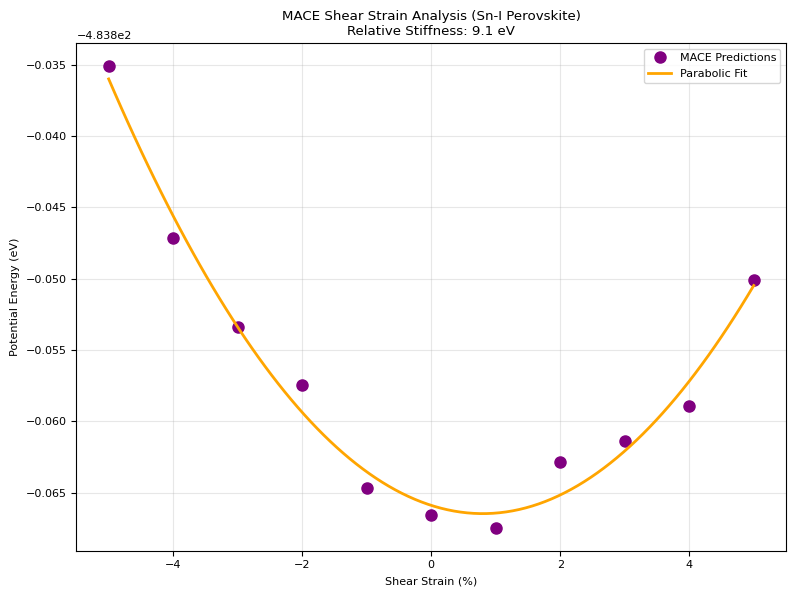

Analysis complete! Plot saved to /content/mace_shear_strain.png


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from ase.io import read
from ase.optimize import LBFGS
from ase.filters import FrechetCellFilter
from mace.calculators import MACECalculator
from google.colab import drive

drive.mount('/content/drive')


base_dir = '/content/drive/MyDrive/MDProject'
init_structure_path = os.path.join(base_dir, 'valid.extxyz')
model_path = "/content/drive/MyDrive/MDProject/new_simulation/1.NVT_300/A.1_10K/checkpoints/corr2trueL1/model_3000_pts_corr2L1_run-1_stagetwo.model"


print("Loading MACE model and structure")
calc = MACECalculator(model_paths=model_path, device='cuda', default_dtype='float32')
atoms = read(init_structure_path, index=0)
atoms.calc = calc

# 0K Equilibrium
print("\n--- PHASE 1: Relaxing to 0K Equilibrium ---")
ucf = FrechetCellFilter(atoms)
opt = LBFGS(ucf, trajectory=os.path.join(base_dir, 'shear_relaxation.traj'))
opt.run(fmax=0.05, steps=200)

opt_cell = atoms.get_cell()
print("Equilibrium established.")

# We apply a shear strain from -5% to +5%
shear_strains = np.linspace(-0.05, 0.05, 11)
energies = []

for strain in shear_strains:
    atoms_strained = atoms.copy()
    atoms_strained.calc = calc

    # Extract the relaxed 3x3 cell matrix
    cell = opt_cell.copy()

    # Apply pure shear in the XY plane
    # This tilts the Y-axis vector along the X-direction
    cell[0, 1] += strain * cell[1, 1]

    # Set the new slanted cell and scale the atoms with it
    atoms_strained.set_cell(cell, scale_atoms=True)

    opt_internal = LBFGS(atoms_strained, logfile=None)
    opt_internal.run(fmax=0.05, steps=50)

    e = atoms_strained.get_potential_energy()
    energies.append(e)

    print(f"Shear Strain: {strain*100:>5.1f}% | Energy: {e:>10.3f} eV")

# Fitting the Shear Modulus
# For small shear strains, Energy is a parabola: E = E0 + 0.5 * C * strain^2
# We use a 2nd-degree polynomial fit (ax^2 + bx + c)
fit_coeffs = np.polyfit(shear_strains, energies, 2)
curvature = fit_coeffs[0]  # This is proportional to the Shear Modulus

print(f"\n--- RESULTS ---")
print(f"Shear Curvature (Stiffness): {curvature:.2f} eV / strain^2")

# plot
plt.figure(figsize=(8, 6))

# Plot raw data
plt.plot(shear_strains * 100, energies, 'o', color='purple', label='MACE Predictions', markersize=8)

# Plot parabolic fit
strain_fit = np.linspace(min(shear_strains), max(shear_strains), 100)
energy_fit = np.polyval(fit_coeffs, strain_fit)
plt.plot(strain_fit * 100, energy_fit, '-', color='orange', label='Parabolic Fit', linewidth=2)

plt.title(f'MACE Shear Strain Analysis (Sn-I Perovskite)\nRelative Stiffness: {curvature:.1f} eV')
plt.xlabel('Shear Strain (%)')
plt.ylabel('Potential Energy (eV)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

save_path = '/content/mace_shear_strain.png'
plt.savefig(save_path, dpi=300)
plt.show()

print(f"Analysis complete! Plot saved to {save_path}")

--correlation=4

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading MACE model and structure...


/usr/local/lib/python3.13/dist-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)



--- PHASE 1: Relaxing to 0K Equilibrium ---
       Step     Time          Energy          fmax
LBFGS:    0 09:25:59     -479.478821        0.959276
LBFGS:    1 09:26:00     -479.667908        0.918132
LBFGS:    2 09:26:00     -480.048950        0.987943
LBFGS:    3 09:26:01     -480.449860        1.450704
LBFGS:    4 09:26:01     -480.769592        0.905430
LBFGS:    5 09:26:01     -480.956543        0.545952
LBFGS:    6 09:26:01     -481.105865        0.563456
LBFGS:    7 09:26:01     -481.244141        0.702832
LBFGS:    8 09:26:01     -481.365936        0.581192
LBFGS:    9 09:26:02     -481.459900        0.568246
LBFGS:   10 09:26:02     -481.538513        0.398363
LBFGS:   11 09:26:02     -481.618256        0.470171
LBFGS:   12 09:26:02     -481.695587        0.446506
LBFGS:   13 09:26:02     -481.764740        0.425883
LBFGS:   14 09:26:02     -481.831146        0.396974
LBFGS:   15 09:26:03     -481.901764        0.396176
LBFGS:   16 09:26:03     -481.975342        0.387965
LBF

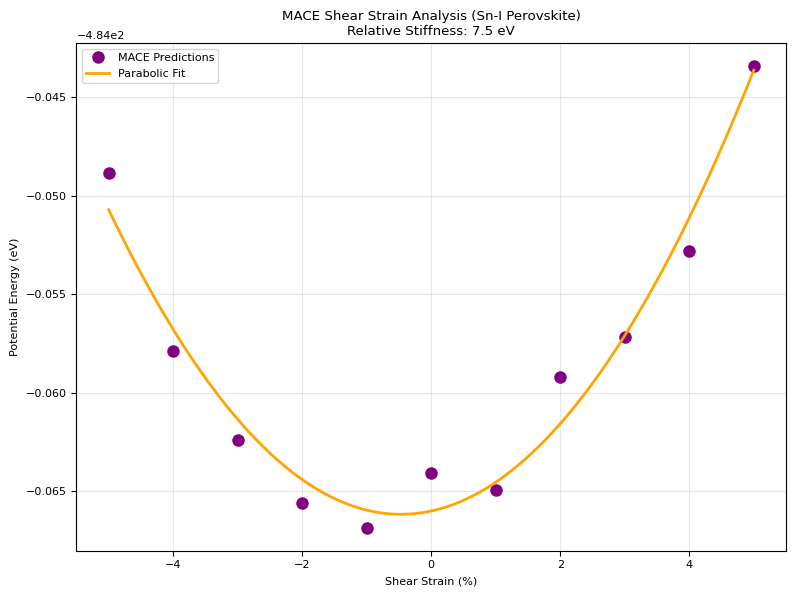

Analysis complete! Plot saved to /content/mace_shear_strain.png


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from ase.io import read
from ase.optimize import LBFGS
from ase.filters import FrechetCellFilter
from mace.calculators import MACECalculator
from google.colab import drive


drive.mount('/content/drive')


base_dir = '/content/drive/MyDrive/MDProject'
init_structure_path = os.path.join(base_dir, 'valid.extxyz')
model_path = "/content/drive/MyDrive/MDProject/new_simulation/1.NVT_300/A.1_10K/checkpoints/corr4trueL1/model_3000_pts_corr4L1_run-1_stagetwo.model"


print("Loading MACE model and structure...")
calc = MACECalculator(model_paths=model_path, device='cuda', default_dtype='float32')
atoms = read(init_structure_path, index=0)
atoms.calc = calc

# 0K Equilibrium
print("\n--- PHASE 1: Relaxing to 0K Equilibrium ---")
ucf = FrechetCellFilter(atoms)
opt = LBFGS(ucf, trajectory=os.path.join(base_dir, 'shear_relaxation.traj'))
opt.run(fmax=0.05, steps=200)

opt_cell = atoms.get_cell()
print("Equilibrium established.")

# Applying Macroscopic Shear Strain
# We apply a shear strain from -5% to +5%
shear_strains = np.linspace(-0.05, 0.05, 11)
energies = []

for strain in shear_strains:
    atoms_strained = atoms.copy()
    atoms_strained.calc = calc

    # Extract the relaxed 3x3 cell matrix
    cell = opt_cell.copy()

    # Apply pure shear in the XY plane
    # This tilts the Y-axis vector along the X-direction
    cell[0, 1] += strain * cell[1, 1]

    # Set the new slanted cell and scale the atoms with it
    atoms_strained.set_cell(cell, scale_atoms=True)

    # Internal relaxation is CRITICAL here. The atoms must be allowed to
    # wiggle and rotate to accommodate the slanted box.
    opt_internal = LBFGS(atoms_strained, logfile=None)
    opt_internal.run(fmax=0.05, steps=50)

    e = atoms_strained.get_potential_energy()
    energies.append(e)

    print(f"Shear Strain: {strain*100:>5.1f}% | Energy: {e:>10.3f} eV")

# For small shear strains, Energy is a parabola: E = E0 + 0.5 * C * strain^2
# We use a 2nd-degree polynomial fit (ax^2 + bx + c)
fit_coeffs = np.polyfit(shear_strains, energies, 2)
curvature = fit_coeffs[0]  # This is proportional to the Shear Modulus


print(f"Shear Curvature (Stiffness): {curvature:.2f} eV / strain^2")

plt.figure(figsize=(8, 6))

# Plot raw data
plt.plot(shear_strains * 100, energies, 'o', color='purple', label='MACE Predictions', markersize=8)

# Plot parabolic fit
strain_fit = np.linspace(min(shear_strains), max(shear_strains), 100)
energy_fit = np.polyval(fit_coeffs, strain_fit)
plt.plot(strain_fit * 100, energy_fit, '-', color='orange', label='Parabolic Fit', linewidth=2)

plt.title(f'MACE Shear Strain Analysis (Sn-I Perovskite)\nRelative Stiffness: {curvature:.1f} eV')
plt.xlabel('Shear Strain (%)')
plt.ylabel('Potential Energy (eV)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

save_path = '/content/mace_shear_strain.png'
plt.savefig(save_path, dpi=300)
plt.show()

print(f"Analysis complete! Plot saved to {save_path}")

In [ ]:
! pip install ase
! pip install pymbar
! pip install mace-torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 45.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.4/107.4 kB 4.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 316.0/316.0 kB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 387.7/387.7 kB 40.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 222.8/222.8 kB 26.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 346.8/346.8 kB 38.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 457.5/457.5 kB 47.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 75.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.8/62.8 kB 7.8 MB/s eta 0:00:00
  Created wheel for python-hostlist: filename=python_hostlist-2.3.0-py3-none-any.whl size=39523 sha256=5483fb50c1d32d8df5abe96cc003cc392ed0b17f46d2aa654afae40a85b6ef73
  Stored in directory: /root/.cache/pip/wheels/05/2e/7e/39f980a5a0755f